# 2D Navier-Stokes in `dynestyx`

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

In [2]:
import os

import exponax
import exponax as ex
import jax.numpy as jnp
import jax.random as jr
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from IPython.display import HTML

import dynestyx as dsx
from dynestyx import (
    DeterministicStateEvolution,
    DynamicalModel,
    LayoutCollection,
)

# Defining the PDE dynamics

A forward simulation of the two-dimensional incompressible Navier-Stokes equations as a
single `dynestyx.DynamicalModel`. This is the 2D counterpart of the 3D Navier-Stokes tutorial:
the forcing, viscosity, drag, observation model and filter are the same.

In two dimensions the vorticity $\omega = \partial_x u_y - \partial_y u_x$ is a scalar, and
the equations are usually written in streamfunction-vorticity form,

$$
\partial_t \omega + (\mathbf{u}\cdot\nabla)\,\omega = \nu \Delta \omega + \lambda \omega + f_\omega,
\qquad
\mathbf{u} = (\partial_y \psi, -\partial_x \psi),
\qquad
\Delta \psi = -\omega .
$$

$\nu$ is the viscosity and $\lambda$ a weak drag. The velocity is recovered from the
streamfunction $\psi$, so $\nabla \cdot \mathbf{u} = 0$ holds by construction: unlike in 3D,
no Leray projection is needed, and the state of the model is the vorticity field alone.
The Kolmogorov forcing

$$
\mathbf{f} = (\gamma \sin(k \tfrac{2\pi}{L} y), 0)
\quad\Longrightarrow\quad
f_\omega = -\gamma k \tfrac{2\pi}{L} \cos(k \tfrac{2\pi}{L} y)
$$

injects energy so the turbulence is sustained.

The observations are a coarse-grained version of the vorticity, polluted by Gaussian noise:

$$
y_t = G * \omega_t + \varepsilon_t
$$



We use [`exponax`](https://fkoehler.site/exponax/) spectral solver. In this case, the dynamics are deterministic: the transition returns a `Delta` distribution.

In [3]:
domain_extent = float(2 * jnp.pi) # periodic box (0, L)^2
dt_obs = 0.25                     # the dynestyx model time step

num_points = 64                   # grid points per axis. Warning: increasing this means also increasing the number of solver substeps.
solver_substeps = 10              # how many internal solver steps per observation step. Heuristic: N = 128 needs 25 substeps, N = 64 needs 10 substeps, N = 32 needs 5 substeps. This is to ensure stability of the solver.
observation_points = 16           # grid points per axis of the observations, independent of num_points. 16 keeps the forcing (k = 4) and ~92% of the vorticity variance.

# Parameters of the PDE 
viscosity = 0.005                  # nu
drag = -0.1                        # lambda
injection_mode = 4                 # forcing wavenumber k


axis = jnp.linspace(0, domain_extent, num_points, endpoint=False)

# The warmup starts from a random vorticity field. Any scalar field is a valid 2D vorticity,
# so no projection is needed.
random_ic = ex.ic.RandomTruncatedFourierSeries(2, cutoff=2, std_one=True)
u_random_init = random_ic(num_points, key=jr.key(0))  # (1, N, N) vorticity field

In [4]:
# Defining a PDE stepper
def make_pde_stepper(num_points, dt_obs):
    # Defining the PDE stepper
    dt_solver = dt_obs / solver_substeps 
    pde_stepper = exponax.RepeatedStepper(
        exponax.stepper.KolmogorovFlowVorticity(
            num_spatial_dims=2,
            domain_extent=domain_extent,
            num_points=num_points,
            dt=dt_solver,
            diffusivity=viscosity,
            drag=drag,
            injection_mode=injection_mode,
            order=4,  
        ),
        solver_substeps,
    )
    return pde_stepper

pde_step = make_pde_stepper(num_points, dt_obs)

# Downsampling operator
def observation_function(state):
    return exponax.map_between_resolutions(state, observation_points)

layouts = LayoutCollection.from_example(
    state=u_random_init,
    observation=observation_function(u_random_init),
)


def step(x, u, t_now, t_next):
    state = layouts.state.unflatten(x)          # flat vector -> (1, N, N) vorticity field
    return layouts.state.flatten(pde_step(state))
evolution = DeterministicStateEvolution(F=step)

observation_sd = 0.1 * 4.0  # ~10% of the standard deviation of the turbulent vorticity
def observation_model(x, u, t):
    state = layouts.state.unflatten(x)
    observation = observation_function(state)
    observation = layouts.observation.flatten(observation)
    return dist.Normal(observation, observation_sd).to_event(1)

def make_dynamics(u0):
    x0 = layouts.state.flatten(u0)
    initial_condition = dist.Delta(x0, event_dim=1)
    return DynamicalModel(
        initial_condition=initial_condition,
        state_evolution=evolution,
        observation_model=observation_model,
    )

# Warmup

The random initial condition is far from the turbulent regime. We first run the flow for `T_warmup` seconds and
keep only its final state, `u_warmup`, which is the initial condition of the simulation below.

In [5]:
T_warmup = 25.0
warmup_times = jnp.arange(0.0, T_warmup + dt_obs, step=dt_obs)

warmup_dynamics = make_dynamics(u_random_init)
warmup_result = dsx.simulate(
    warmup_dynamics,
    rng_key=jr.key(0),
    predict_times=warmup_times,
)
u_warmup = layouts.state.unflatten(warmup_result.states[0, -1])  # state at t = T_warmup
assert jnp.isfinite(u_warmup).all()
del warmup_result  # only the final state is needed

# Simulation

In [6]:
T = 75.0
times = jnp.arange(0.0, T, step=dt_obs)

dynamics = make_dynamics(u_warmup)
result = dsx.simulate(
    dynamics,
    rng_key=jr.key(13),
    predict_times=times,
)
result = result.unflatten(layouts)  # flat vectors -> (n_simulations, time, 1, N, N) fields
states = result.states[0]
observations = result.observations[0]
assert jnp.isfinite(states).all()
del result  # states and observations hold everything used below

# Vorticity field

Snapshots of the vorticity. The forcing drives shear layers along $y$, which roll up into
vortices of both signs that merge and are stretched into thin filaments.

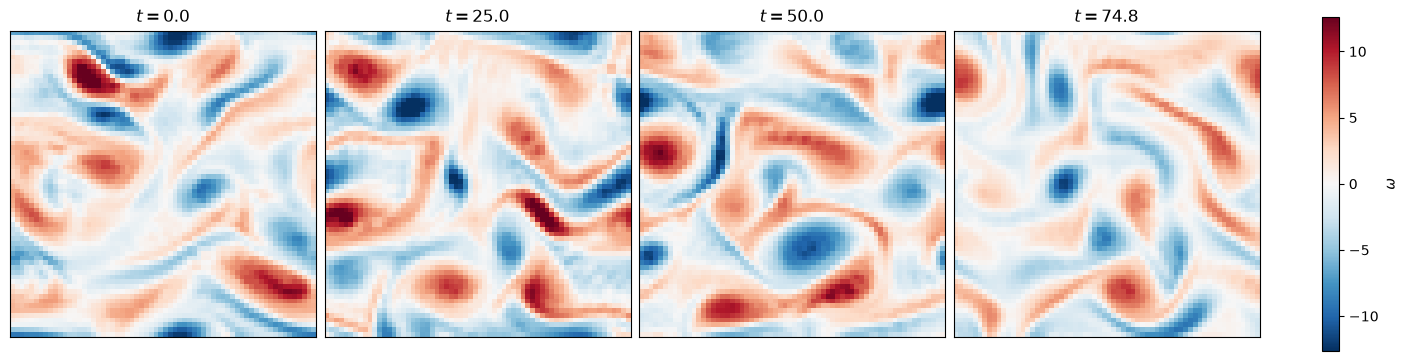

In [7]:
# Vorticity is signed, so we use a diverging colour map, symmetric around zero.
# The colour scale is set by the true state and shared by every plot below.
colour_max = float(np.percentile(np.abs(np.asarray(states)), 99.5))
imshow_kwargs = dict(
    origin="lower", extent=(0, domain_extent, 0, domain_extent),
    cmap="RdBu_r", vmin=-colour_max, vmax=colour_max, interpolation="nearest",
)

snapshot_times = (0.0, T / 3, 2 * T / 3, times[-1])
fig, axes = plt.subplots(1, len(snapshot_times), figsize=(14, 3.8), constrained_layout=True)
for ax, t in zip(axes, snapshot_times):
    index = int(jnp.argmin(jnp.abs(times - t)))
    # Fields are indexed (x, y): transpose so x is horizontal and y vertical.
    image = ax.imshow(np.asarray(states[index, 0]).T, **imshow_kwargs)
    ax.set_title(f"$t = {float(times[index]):.1f}$")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(image, ax=axes, shrink=0.9, label=r"$\omega$")
plt.show()

# Filtering

In [8]:
from dynestyx import Filter
from dynestyx.inference.filters import EnKFConfig

In [9]:
# Only the filtered ensemble is used below: the predicted-observation outputs (which include
# observation_dim x observation_dim covariances) and the NumPyro record_* sites are turned off.
filter_config = EnKFConfig(
    n_particles=8,
    ensemble_subspace=True,
    include_predicted_observations=False,
    record_filtered_states_mean=False,
    record_filtered_states_cov=False,
    record_filtered_states_cov_diag=False,
    record_filtered_states_chol_cov=False,
    record_filtered_particles=False,
    record_predicted_observations_mean=False,
    record_predicted_observations_cov=False,
    record_predicted_observations_ensemble=False,
)

In [10]:
def make_dynamics_filter(u0, ic_variance):
    x0 = layouts.state.flatten(u0)
    initial_condition = dist.Normal(x0, jnp.sqrt(ic_variance)).to_event(1)
    return DynamicalModel(
        initial_condition=initial_condition,
        state_evolution=evolution,
        observation_model=observation_model,
    )

# The filter's prior over the initial state: a small Gaussian spread around the warmed-up state.
# With a Dirac initial condition all members would be identical, and the EnKF update would do nothing.
# The vorticity is ~10x larger than the 3D velocity, so the variance is scaled up by 100.
filter_dynamics = make_dynamics_filter(u_warmup, ic_variance=1e-1)

obs_times = times
obs_values = layouts.observation.flatten(observations)

In [11]:
with Filter(filter_config):
    filter_result = dsx.condition(
        "u",
        filter_dynamics,
        obs_times=obs_times,
        obs_values=obs_values,
    )

# Ensemble mean at each observation time. The result holds the full ensemble at every step
# (and copies of it in filter_result.dists): free it before unflattening the mean.
filtered_mean = filter_result.states.ensemble.mean(axis=1)
del filter_result, obs_values
filtered_states = layouts.state.unflatten(filtered_mean)  # (time, 1, N, N) vorticity fields
del filtered_mean

# Filtered state

The true state, the observations and the EnKF mean, side by side. The observation is drawn on
its own coarse grid, without interpolation.

In [12]:
anim_stride = 1           # frames to animate = n_steps // anim_stride

filtered_fields = tuple(
    np.asarray(fields[::anim_stride, 0], dtype=np.float32)
    for fields in (states, observations, filtered_states)
)
filtered_titles = (r"$\mathrm{True\ state}$", r"$\mathrm{Observation}$", r"$\mathrm{Filtered}$")

fig, filtered_axes = plt.subplots(1, 3, figsize=(13.8, 4.8), dpi=76, facecolor="white")
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.03, top=0.86, wspace=0.04)
filtered_images = []
for ax, field, title in zip(filtered_axes, filtered_fields, filtered_titles):
    filtered_images.append(ax.imshow(field[0].T, **imshow_kwargs))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=18, pad=10, math_fontfamily="cm")
time_label = fig.suptitle("", fontsize=12)


def draw_filtered(frame):
    for image, field in zip(filtered_images, filtered_fields):
        image.set_data(field[frame].T)
    time_label.set_text(f"t = {float(times[frame * anim_stride]):.2f}")
    return filtered_images


draw_filtered(0)
filtered_ani = animation.FuncAnimation(
    fig, draw_filtered, frames=filtered_fields[0].shape[0], interval=110
)
plt.close(fig)

os.makedirs("videos", exist_ok=True)
filtered_path = os.path.join("videos", "vorticity_2d_filtered.mp4")
filtered_ani.save(
    filtered_path, writer="ffmpeg", fps=18, dpi=76,
    extra_args=["-pix_fmt", "yuv420p", "-crf", "28"],
    savefig_kwargs={"facecolor": "white"},
)
print(f"wrote {filtered_path}: {os.path.getsize(filtered_path) / 1e6:.2f} MB")
del filtered_ani
HTML(f'<video src="{filtered_path}" controls loop width="1380"></video>')

wrote videos/vorticity_2d_filtered.mp4: 2.34 MB


The same comparison at a few fixed times, followed by the relative error of the filtered mean.
With only 8 ensemble members for a 4096-dimensional state, the EnKF follows the flow at first but
gradually drifts away from it: the ensemble cannot span all the active modes of the turbulence.

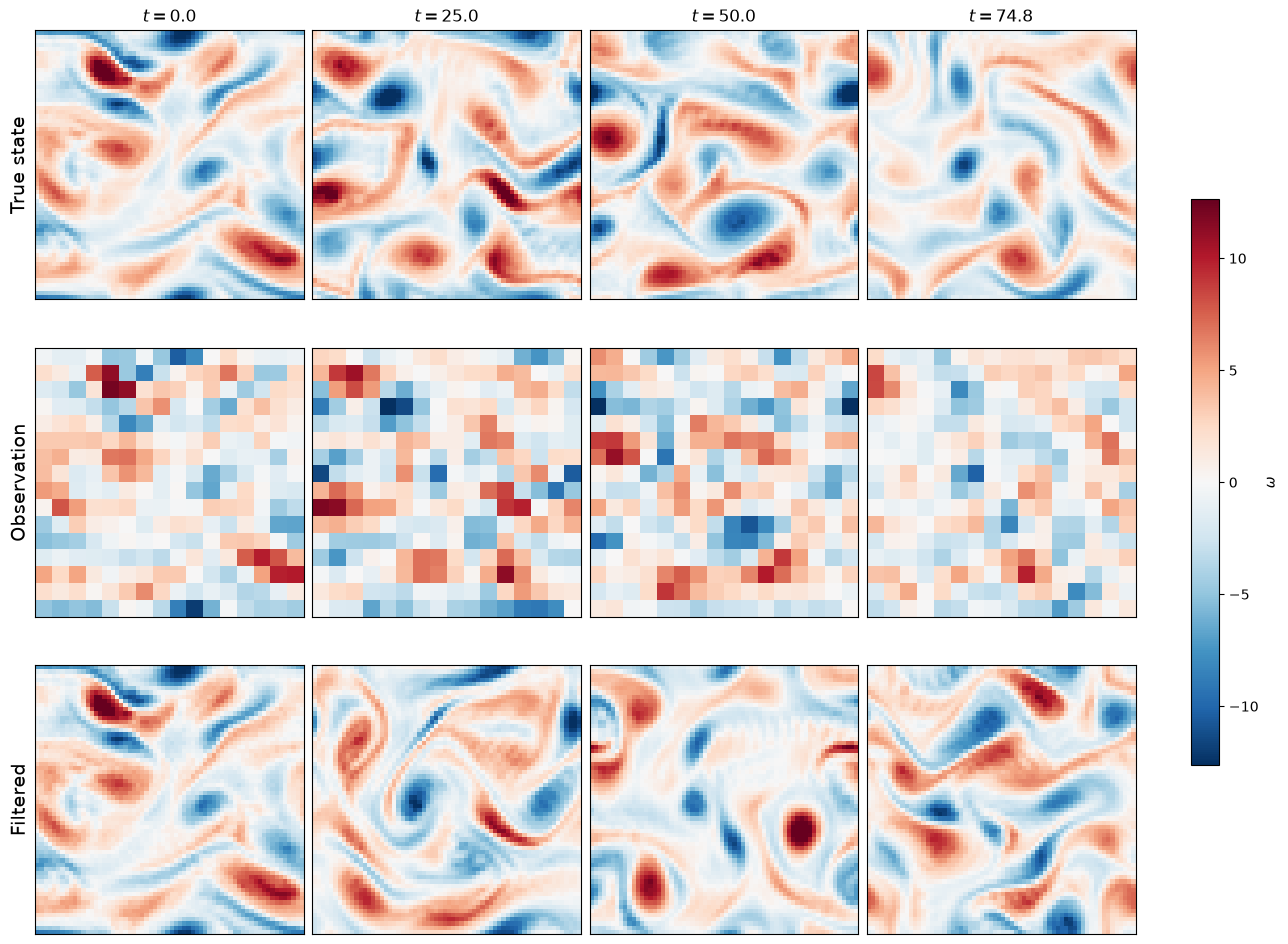

relative L2 error of the filtered mean: 0.048 at t = 0, 1.121 on average, 1.525 at t = 74.8


In [13]:
snapshot_indices = [int(jnp.argmin(jnp.abs(times - t))) for t in snapshot_times]
fig, axes = plt.subplots(
    3, len(snapshot_indices), figsize=(3.2 * len(snapshot_indices), 9.6), constrained_layout=True
)
for row, (fields, title) in enumerate(zip((states, observations, filtered_states), filtered_titles)):
    for col, index in enumerate(snapshot_indices):
        ax = axes[row, col]
        image = ax.imshow(np.asarray(fields[index, 0]).T, **imshow_kwargs)
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(f"$t = {float(times[index]):.1f}$")
        if col == 0:
            ax.set_ylabel(title, fontsize=14)
fig.colorbar(image, ax=axes, shrink=0.6, label=r"$\omega$")
plt.show()

relative_error = jnp.linalg.norm((filtered_states - states).reshape(len(times), -1), axis=1) / (
    jnp.linalg.norm(states.reshape(len(times), -1), axis=1)
)
print(f"relative L2 error of the filtered mean: {float(relative_error[0]):.3f} at t = 0, "
      f"{float(relative_error.mean()):.3f} on average, {float(relative_error[-1]):.3f} at t = {float(times[-1]):.1f}")